<a href="https://colab.research.google.com/github/Kielson-Luna/macroeconomic-growth-analysis/blob/main/Graficos_Crecimiento_Econ%C3%B3mico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Opcional: mejorar estilo visual
plt.style.use("seaborn-v0_8")
sns.set_theme()

# Mostrar gráficos en notebook
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##                                         **PIB PERCAPITA BOLIVIA**

In [ ]:
ruta_pib = "/content/drive/MyDrive/Datos Bolivia/PIB PER CAPITA/API_NY.GDP.PCAP.PP.KD_DS2_en_csv_v2_4572.csv"

df_pib = pd.read_csv(ruta_pib, skiprows=4)

In [ ]:
#Seleccionar bolivia, por nombre no por cordenadas. Si mañana el Banco Mundial reordena los países, tu código sigue funcionando.
df_bolivia = df_pib[df_pib["Country Name"] == "Bolivia"]
df_bolivia.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
28,Bolivia,BOL,"GDP per capita, PPP (constant 2021 internation...",NY.GDP.PCAP.PP.KD,NaN,NaN,NaN,NaN,NaN,NaN,...,11755.25562,11920.313508,11930.915915,10285.659075,11202.440984,11487.71488,11616.15756,11329.151806,NaN,NaN


In [ ]:
df_bolivia = df_pib[df_pib["Country Name"] == "Bolivia"]

df_bolivia_1990 = df_bolivia.loc[:, "1990":]

In [ ]:
df_bolivia_1990 = df_bolivia_1990.T
df_bolivia_1990.columns = ["PIB_per_capita"]
df_bolivia_1990.index.name = "Year"

df_bolivia_1990.head()

,PIB_per_capita
Year,
1990,6247.104466
1991,6440.485716
1992,6414.328668
1993,6556.816403
1994,6731.284874


In [ ]:
#Estás obligando a una columna a convertirse en números reales, y todo lo que no pueda convertirse lo transformas en “dato vacío”.

# ejemplo  Antes de usar el codigo ["1200", "1350", "no data", "980"] --> Despues [1200.0, 1350.0, NaN, 980.0]
#Resumen Convierte esta columna a números reales, y si algo no encaja, mándalo al limbo estadístico (NaN)

df_bolivia_1990["PIB_per_capita"] = pd.to_numeric(df_bolivia_1990["PIB_per_capita"], errors="coerce")

In [ ]:
import numpy as np
# Crea columna de "ln(pib pc)" en el mismo datraframe que ya tenemos
# el logaritmo no es otro dato distinto. Es una transformación del mismo dato.

df_bolivia_1990["ln_PIB_per_capita"] = np.log(df_bolivia_1990["PIB_per_capita"])

In [ ]:
df_bolivia_1990.to_csv("/content/drive/MyDrive/Datos Bolivia/bolivia_pibpc_limpio.csv", index=True)
#Crea un csv limpio y lo guarda en la misma ruta, pero sin inferir en la carpeta de datos originales

In [ ]:
df_bolivia_1990.index

Index(['1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998',
       '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007',
       '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016',
       '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025',
       'Unnamed: 70'],
      dtype='object', name='Year')

In [ ]:
# Eliminar filas cuyo índice no sea año numérico
df_bolivia_1990 = df_bolivia_1990[df_bolivia_1990.index.str.isnumeric()]

In [ ]:
#Que el índice sea numérico.

#Que el PIB sea numérico.
df_bolivia_1990.index = df_bolivia_1990.index.astype(int)

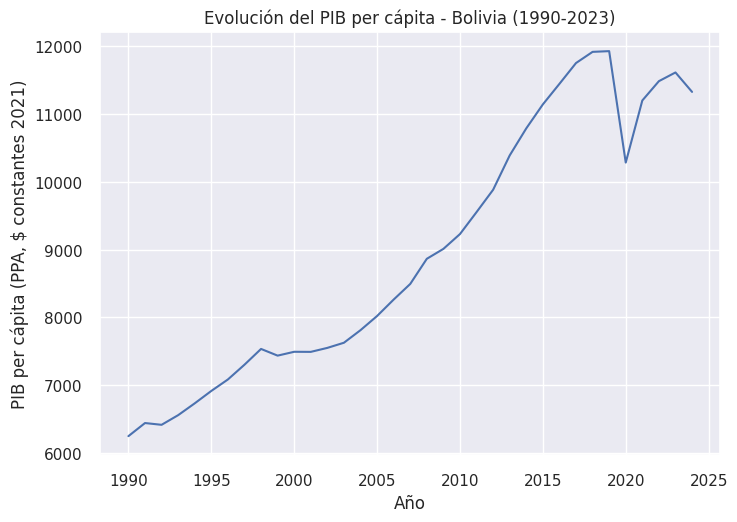

In [ ]:
import matplotlib.pyplot as plt

plt.figure()

plt.plot(df_bolivia_1990.index,
         df_bolivia_1990["PIB_per_capita"])

plt.xlabel("Año")
plt.ylabel("PIB per cápita (PPA, $ constantes 2021)")
plt.title("Evolución del PIB per cápita - Bolivia (1990-2023)")

plt.show()

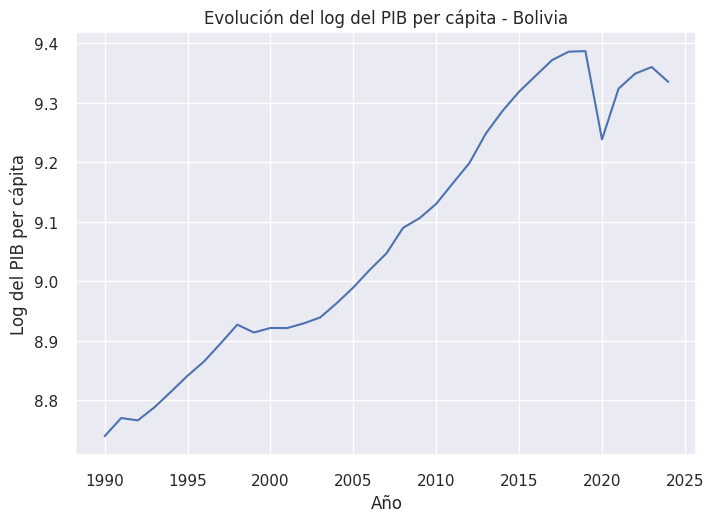

In [ ]:
plt.figure()

plt.plot(df_bolivia_1990.index,
         np.log(df_bolivia_1990["PIB_per_capita"]))

plt.xlabel("Año")
plt.ylabel("Log del PIB per cápita")
plt.title("Evolución del log del PIB per cápita - Bolivia")

plt.show()

In [ ]:
df_bolivia_1990["growth_rate"] = (
    df_bolivia_1990["PIB_per_capita"].pct_change(fill_method=None)
)

## MORTALIDAD INFANTIL BOLIVIA

---



In [ ]:
ruta_mortal = "//content/drive/MyDrive/Datos Bolivia/TASA MORTALIDAD/API_SP.DYN.IMRT.IN_DS2_es_csv_v2_21895.csv"

df_mortal = pd.read_csv(ruta_mortal, skiprows=4)

In [ ]:
df_mortalhori = df_mortal[df_mortal["Country Name"] == "Bolivia"]
df_mortalhori.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
28,Bolivia,BOL,Tasa de mortalidad infantil (por cada 1.000 na...,SP.DYN.IMRT.IN,187.4,184.5,181.5,178.6,175.7,172.7,...,24.8,23.9,23.0,22.2,21.4,20.7,20.0,NaN,NaN,NaN


In [ ]:
df_mortalhori = df_mortal[df_mortal["Country Name"] == "Bolivia"]

df_mortalhori_1960 = df_mortalhori.loc[:, "1960":]

In [ ]:
df_mortalhori_1960 = df_mortalhori_1960.T
df_mortalhori_1960.columns = ["TASA DE MORTALIDAD INFANTIL"]
df_mortalhori_1960.index.name = "Year"

df_mortalhori_1960.head()

,TASA DE MORTALIDAD INFANTIL
Year,
1960,187.4
1961,184.5
1962,181.5
1963,178.6
1964,175.7


In [ ]:
df_mortalhori_1960["TASA DE MORTALIDAD INFANTIL"] = pd.to_numeric(df_mortalhori_1960["TASA DE MORTALIDAD INFANTIL"], errors="coerce")

In [ ]:
df_mortalhori_1960.to_csv("/content/drive/MyDrive/Datos Bolivia/bolivia_mortalidad infantil_limpio.csv", index=True)

## TODOS LOS PAISES, SCATERPLOT

In [ ]:
# Rutas
ruta_pib = "/content/drive/MyDrive/Datos Bolivia/PIB PER CAPITA/API_NY.GDP.PCAP.PP.KD_DS2_en_csv_v2_4572.csv"
ruta_mort = "/content/drive/MyDrive/Datos Bolivia/TASA MORTALIDAD/API_SP.DYN.IMRT.IN_DS2_es_csv_v2_21895.csv"

# Cargar saltando metadatos
df_pibmundial = pd.read_csv(ruta_pib, skiprows=4)
df_mortmundial = pd.read_csv(ruta_mort, skiprows=4)

In [ ]:
anio = "2023"

In [ ]:
df_pib_year = df_pibmundial[["Country Name", anio]].copy()
df_mort_year = df_mortmundial[["Country Name", anio]].copy()

df_pib_year.columns = ["Country", "PIB_per_capita"]
df_mort_year.columns = ["Country", "Mortality"]

In [ ]:
df_pib_year["PIB_per_capita"] = pd.to_numeric(df_pib_year["PIB_per_capita"], errors="coerce")
df_mort_year["Mortality"] = pd.to_numeric(df_mort_year["Mortality"], errors="coerce")

In [ ]:
df_merged = pd.merge(df_pib_year, df_mort_year, on="Country")
df_merged = df_merged.dropna()

In [ ]:
df_merged["ln_PIB"] = np.log(df_merged["PIB_per_capita"])

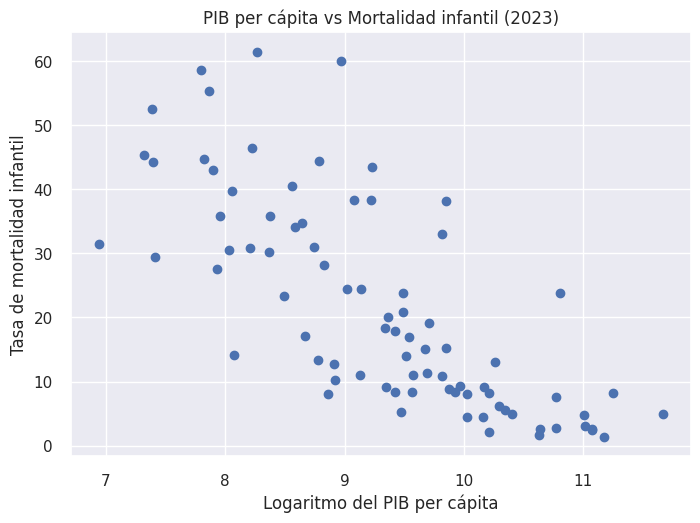

In [ ]:
plt.figure()
plt.scatter(df_merged["ln_PIB"], df_merged["Mortality"])

plt.xlabel("Logaritmo del PIB per cápita")
plt.ylabel("Tasa de mortalidad infantil")
plt.title(f"PIB per cápita vs Mortalidad infantil ({anio})")

plt.show()

# **LABSH, HECHOS DE KALDOR**

In [ ]:
# 1. Definir la ruta
ruta_trabajo = "/content/drive/MyDrive/Datos Bolivia/labsh/kaldor trabajo(Data) (1).csv"

# 2. Cargar el dataset especificando el separador y la codificación
# Agregamos encoding='latin-1' para evitar el UnicodeDecodeError
df_trabajo = pd.read_csv(ruta_trabajo, sep=None, engine='python', encoding='latin-1')

# 3. Crear el dataframe filtrado para Bolivia
# Usamos str.contains para ser más flexibles con el nombre exacto
df_trabajobolivia = df_trabajo[df_trabajo['country'].str.contains('Bolivia', na=False)][['year', 'labsh']].copy()

# 4. Mostrar las primeras filas para verificar la carga
print(df_trabajobolivia.head())

      year   labsh
1702  1950  0,5132
1703  1951  0,5132
1704  1952  0,5132
1705  1953  0,5132
1706  1954  0,5132


In [ ]:
# Primero, convertimos la columna labsh a números reales reemplazando la coma por punto
df_trabajobolivia['labsh'] = df_trabajobolivia['labsh'].str.replace(',', '.').astype(float)

# Ahora el cálculo de capsh funcionará correctamente
df_trabajobolivia['capsh'] = 1 - df_trabajobolivia['labsh']

# Verificamos los primeros resultados
print(df_trabajobolivia.head())

      year   labsh   capsh
1702  1950  0.5132  0.4868
1703  1951  0.5132  0.4868
1704  1952  0.5132  0.4868
1705  1953  0.5132  0.4868
1706  1954  0.5132  0.4868


In [ ]:
df_trabajobolivia.to_csv('/content/drive/MyDrive/Datos Bolivia/bolivia_factores_pib.csv', index=False)

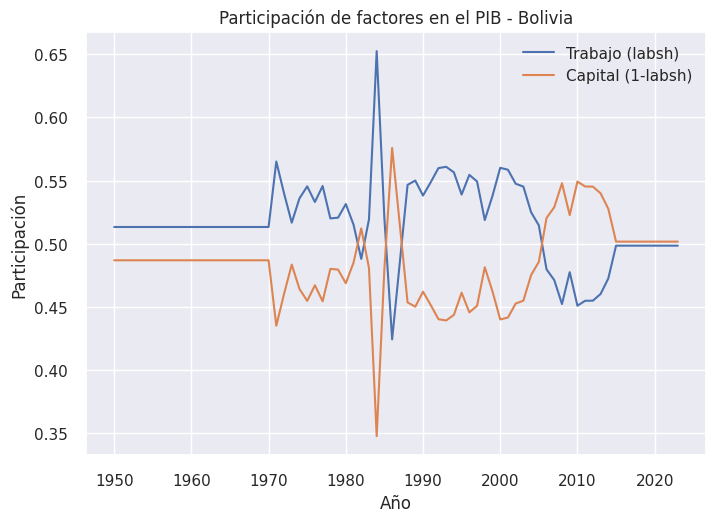

In [ ]:
import matplotlib.pyplot as plt

plt.plot(df_trabajobolivia['year'], df_trabajobolivia['labsh'], label='Trabajo (labsh)')
plt.plot(df_trabajobolivia['year'], df_trabajobolivia['capsh'], label='Capital (1-labsh)')
plt.title('Participación de factores en el PIB - Bolivia')
plt.xlabel('Año')
plt.ylabel('Participación')
plt.legend()
plt.show()

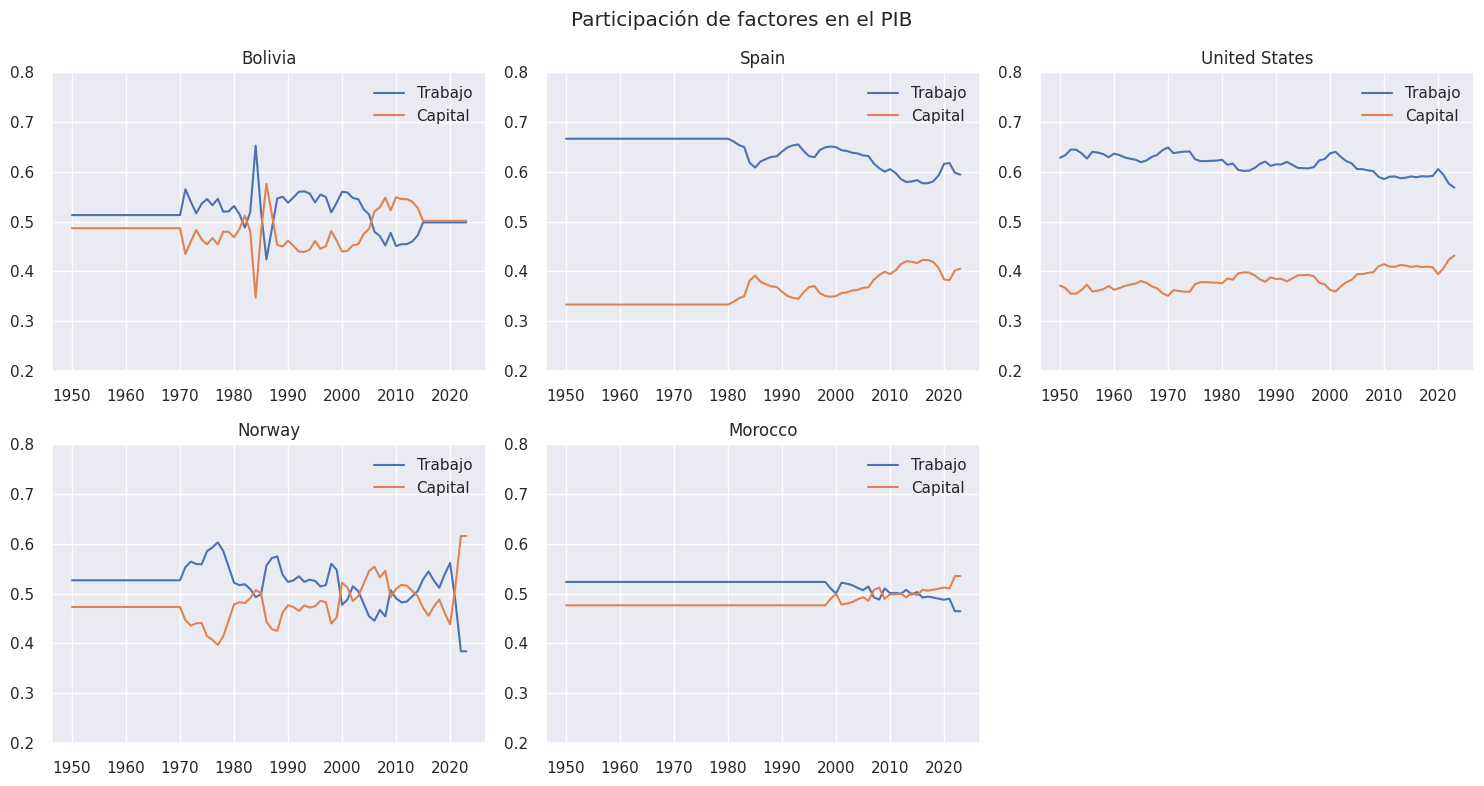

In [ ]:
# Filtrar los países seleccionados
paises = ['Bolivia', 'Spain', 'United States', 'Norway', 'Morocco']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, pais in enumerate(paises):
    df_pais = df_trabajo[df_trabajo['country'].str.contains(pais, na=False)][['year', 'labsh']].copy()

    # Limpieza: Convertir labsh a numérico (reemplazando coma por punto si es necesario)
    if df_pais['labsh'].dtype == 'object':
        df_pais['labsh'] = df_pais['labsh'].str.replace(',', '.').astype(float)

    df_pais['capsh'] = 1 - df_pais['labsh']

    axes[i].plot(df_pais['year'], df_pais['labsh'], label='Trabajo')
    axes[i].plot(df_pais['year'], df_pais['capsh'], label='Capital')
    axes[i].set_title(pais)
    axes[i].set_ylim(0.2, 0.8) # Ajustado para ver mejor las variaciones
    axes[i].legend()

# Ocultar el subplot sobrante
axes[5].set_visible(False)

plt.suptitle('Participación de factores en el PIB')
plt.tight_layout()
plt.show()